# Predicting HER2/EGFR selectivity from ligand structure

**MSBI-565 Computational Biomedicine and Drug Discovery — Final Project**
Instructor: Abdullah Al Mamun

---

This notebook is a narrated end-to-end run of the project. Every step calls the
same functions as the scripts in `src/`, so the numbers here and the numbers in
`results/` are produced by identical code.

**The question.** HER2 (ERBB2) and EGFR (ERBB1) are the two closest members of
the ErbB family and share a near-identical ATP-binding site. Clinical
inhibitors span the whole selectivity range — lapatinib is dual, neratinib is a
covalent pan-HER inhibitor, tucatinib is deliberately HER2-selective to avoid
the skin and gut toxicity that EGFR inhibition causes. So selectivity is a
design objective, and the question is whether ligand structure predicts it.

**Three models:**

| | Target | Trained on |
|---|---|---|
| Model A | `pHER2` | all curated HER2 compounds |
| Model B | `pEGFR` | all curated EGFR compounds |
| Model C | `Δ = pHER2 − pEGFR` | compounds measured against both |

Model C is compared against the naive baseline of subtracting A's and B's
predictions, and both are compared against a ceiling set by measurement noise.

## 0. Setup

In Colab, uncomment the install line. Everything else is pre-installed.

In [3]:
# In Colab, uncomment the next line. RDKit is needed from section 4 onward.
# !pip install -q rdkit

import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root by walking up until src/common.py turns up, so this
# works whether the notebook was opened from the repo root or from notebooks/.
REPO_ROOT = os.getcwd()
while not os.path.isfile(os.path.join(REPO_ROOT, "src", "common.py")):
    parent = os.path.dirname(REPO_ROOT)
    if parent == REPO_ROOT:
        raise RuntimeError(
            "Could not find src/common.py anywhere above the working "
            "directory. Open this notebook from inside the her2-egfr-qsar "
            "repository, or set REPO_ROOT by hand."
        )
    REPO_ROOT = parent

# Make it the working directory, so every "src/..." path in the cells below
# means the same thing no matter where the notebook was started.
os.chdir(REPO_ROOT)
sys.path.insert(0, os.path.join(REPO_ROOT, "src"))

from common import PROC, RAW, FIGS, TABS, SEED, rule, p_activity, ic50_um
from modeling import (scaffold_splits, random_splits, regressors, evaluate,
                      y_scramble, best_row)

print("repo root:", REPO_ROOT)
print("seed     :", SEED)

repo root: C:\Users\Tlmyl\Downloads\MeharryMedicalCollege\Fall 2026\Computational Biomedicine and Drug Discovery (MSBI 565-1)\Possible Projects\her2-egfr-qsar
seed     : 20261109


## 1. The data, and what is wrong with it

The HER2 set was assembled in the Part 1 workshop: every PubChem assay linked
to Gene ID **2064**, triaged down to 253 assays that actually measure ERBB2
inhibition, concatenated into one table.

Before modelling anything, look at what the endpoint column actually contains.

In [5]:
raw = pd.read_csv(os.path.join(RAW, "combined_pubchem_data.csv"))
cat = pd.read_csv(os.path.join(RAW, "combined_pubchem_data_assay_catalogue.csv"))

print(f"rows: {len(raw):,}   assays: {raw['AID'].nunique()}   compounds: {raw['PUBCHEM_CID'].nunique():,}")
print()
print("Activity outcome labels:")
print(raw["PUBCHEM_ACTIVITY_OUTCOME"].value_counts().to_string())

rows: 2,250   assays: 253   compounds: 1,831

Activity outcome labels:
PUBCHEM_ACTIVITY_OUTCOME
Active          1294
Unspecified      900
Inconclusive      52
Inactive           4


**Four `Inactive` compounds.**

That single number decides the project's framing. A classifier needs negatives;
with four of them, any classification result would be an artefact of how
`Unspecified` was treated. `Unspecified` does *not* mean inactive — it means
the depositor did not make a call.

So this is a **regression** problem on the potency value, and saying why in the
report is worth more than a classifier would have been.

In [7]:
print("Endpoint types:")
print(raw["Standard Type"].value_counts().head(8).to_string())
print()
print("Qualifiers (the censoring problem):")
print(raw["Standard Relation"].value_counts().to_string())

Endpoint types:
Standard Type
IC50           1719
Inhibition      245
Kd              126
Activity         86
EC50             19
Ki               13
Selectivity      10
k_off             9

Qualifiers (the censoring problem):
Standard Relation
=     1655
>      396
<      120
<=      15
~        1
>=       1


**The qualifier trap.** 337 rows report `>` and 21 report `<`. A value of
"> 10000 nM" means the compound was inactive up to the highest concentration
tested — its true IC50 is somewhere *above* 10 µM, not equal to it. Treating
those as exact values would compress the inactive tail and flatter every model.
We quantify them, set them aside, and say so.

## 2. Curation and the noise floor

Run the first script. It needs no RDKit: compound identity comes from
`PUBCHEM_CID`, which is PubChem's own structure-derived identifier.

In [9]:
%run -i src/01_explore_her2.py


1. LOADING
raw measurement rows        : 2,250
assays in catalogue         : 300
assays flagged keep=True    : 253
distinct AIDs in data file  : 253
AIDs present but not kept   : 0  (expected 0)

2. CURATION WATERFALL
0. all downloaded rows                       rows= 2,250  compounds= 1,831
1. has a depositor SMILES                    rows= 2,250  compounds= 1,831
2. has a PubChem CID                         rows= 2,250  compounds= 1,831
3. endpoint is IC50/Ki/Kd/EC50               rows= 1,877  compounds= 1,523
4. units are nM                              rows= 1,830  compounds= 1,495
5. exact values only (relation '=')          rows= 1,449  compounds= 1,182

censored rows set aside     : 381
Standard Relation
>     337
<      21
~       1
>=      1

rows carrying a PubChem validity comment: 9
Data Validity Comment
Outside typical range    9
6. no PubChem validity flag                  rows= 1,440  compounds= 1,173
7. 0 < value <= 1 M                          rows= 1,440  compounds= 

### The result that frames everything else

184 compounds in this dataset were measured for HER2 in **more than one
independent study**. Those repeats are independent estimates of the same
quantity, so their disagreement is pure measurement noise.

Pooled within-compound standard deviation:

$$s_{rep}^2 = \frac{\sum_g \sum_i (x_{gi} - \bar{x}_g)^2}{\sum_g (n_g - 1)}$$

which gives **0.63 log units** — and 30% of repeated compounds disagree by more
than a full log unit. Since a perfect model is still scored against a noisy
observation:

$$R^2_{max} = 1 - \frac{s_{rep}^2}{s_{total}^2} \approx 0.69$$

**Any model reporting R² above ~0.69 on this data is measuring analog leakage,
not generalisation.** This is the single most useful number in the project.

,quantity,value
0,compounds with cross-assay repeats,184.0000
1,pooled within-compound SD (log units),0.6297
2,compound-level SD (log units),1.1321
3,median cross-assay range (log units),0.5656
4,90th percentile cross-assay range,1.6260
5,fraction disagreeing by >1 log unit,0.3043
6,ceiling R^2,0.6906
7,ceiling RMSE (log units),0.6297


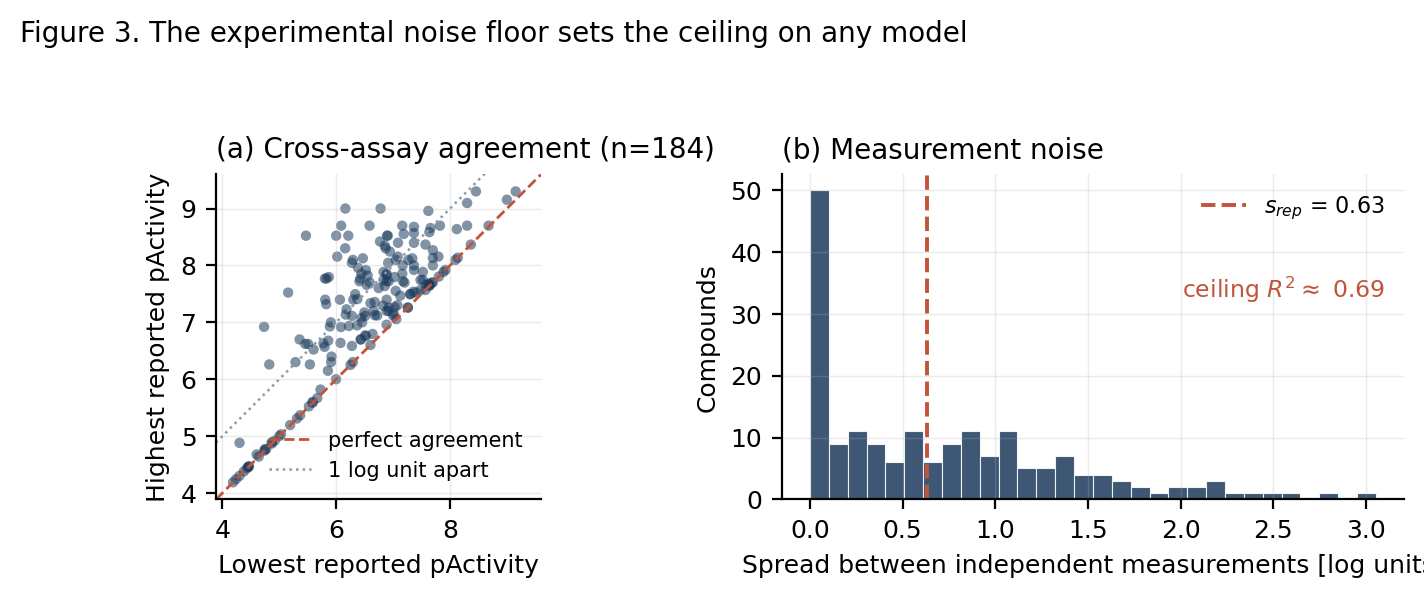

In [14]:
noise = pd.read_csv(os.path.join(TABS, "table3_noise_floor.csv"))
display(noise)

from IPython.display import Image, display as show
show(Image(os.path.join(FIGS, "fig3_noise_floor.png")))

### Why this matters doubly for selectivity

Δ = pHER2 − pEGFR is a **difference** of two independent noisy measurements, so
variances add:

$$s_\Delta = \sqrt{s_{HER2}^2 + s_{EGFR}^2} \approx \sqrt{2} \times 0.63 \approx 0.89$$

Meanwhile Δ's dynamic range is *narrower* than pHER2's, because most ErbB
inhibitors are somewhat active on both targets. Noise up, signal down — so the
selectivity ceiling must sit well below 0.69. That is the project's
quantitative prediction, and Section 6 tests it.

## 3. The EGFR half

`02_fetch_egfr.py` pulls Gene ID **1956** from PubChem and auto-triages the
assay list. Two drops matter most:

- **Mutant EGFR assays** (`L858R`, `T790M`, `E746-A750del`, …). Gefitinib is
  ~100× more potent on L858R than on wild type; pooling mutants into one
  "EGFR" endpoint would make Δ meaningless.
- **Cell proliferation / viability assays.** They measure whether cells died,
  which depends on permeability and efflux as well as target engagement. The
  HER2 side is biochemical, so the EGFR side must be too.

Run with `--catalogue-only` first, **review the catalogue by hand**, then
download. The auto-triage is a first pass, not an oracle.

In [17]:
# Needs internet. Takes a few minutes.
# !python src/02_fetch_egfr.py --catalogue-only
# ... review data/raw/egfr_assay_catalogue.csv ...
# !python src/02_fetch_egfr.py --download-only

cat_path = os.path.join(RAW, "egfr_assay_catalogue.csv")
if os.path.exists(cat_path):
    ec = pd.read_csv(cat_path)
    print(f"EGFR assays found: {len(ec):,}   kept: {int(ec['keep'].sum()):,}")
    print()
    print(ec.loc[~ec["keep"], "drop_reason"].value_counts().to_string())
else:
    print("Not downloaded yet -- run 02_fetch_egfr.py")

Not downloaded yet -- run 02_fetch_egfr.py


## 4. Standardisation and the matched set

Both targets go through an **identical** chain:

> largest organic fragment → neutralise charges → canonical isomeric SMILES

The symmetry is not cosmetic. If the two sides were canonicalised differently
the join would fail and the matched set would silently shrink. Neutralisation
in particular matters: without it, a free base and its hydrochloride become two
different compounds, the replicate is missed, and the pair can land on opposite
sides of a split.

In [20]:
%run -i src/03_curate.py


CURATING HER2
  downloaded rows                       2,250
  assay passed target triage            2,250
  has depositor SMILES                  2,250
  endpoint is a potency                 1,877
  units are nM                          1,830
  exact value (relation '=')            1,449
  no PubChem validity flag              1,440
  0 < value <= 1 M                      1,440
  structure parsed and standardised     1,431

  -> 1,162 unique compounds
     pHER2: 4.03 to 9.23  (median 6.78, SD 1.14)

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
No EGFR data found at data/raw/egfr_pubchem_data.csv
Run:  python src/02_fetch_egfr.py
Only the HER2 table has been written; the matched set is skipped.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!


In [21]:
mpath = os.path.join(PROC, "matched_set.csv")
if os.path.exists(mpath):
    matched = pd.read_csv(mpath)
    print(f"matched compounds: {len(matched):,}")
    print()
    print(matched["delta"].describe().round(3).to_string())
    from IPython.display import Image, display as show
    show(Image(os.path.join(FIGS, "fig5_selectivity_landscape.png")))
else:
    print("Run 02 and 03 first.")

Run 02 and 03 first.


## 5. Features and scaffolds

Three representations, computed once on every compound so each model is judged
on exactly the same molecules:

1. **Lipinski (8)** — interpretable physicochemistry. Fast, but blind to isomers.
2. **Morgan FP (1024)** — circular fingerprint, radius 2. The standard QSAR baseline.
3. **RDKit 2D (~200)** — every 2D descriptor. More information, far more noise.

And the **Bemis-Murcko scaffold** of each compound, which is what we group by
when splitting. A random split puts close analogs on both sides of the fence;
the model is then tested on molecules differing from a training molecule by a
methyl group, scores brilliantly, and tells you nothing.

In [25]:
%run -i src/04_features.py


FEATURISING HER2
compounds: 1,162   unparseable: 0
  Lipinski (8)           shape (1162, 8)
  Morgan FP (1024)       shape (1162, 1024)
  RDKit 2D (217)         shape (1162, 217)

unique Bemis-Murcko scaffolds: 467  (0.40 per compound)

largest chemical series (the analog bias, made visible):
    76 compounds  c1ccc(Nc2ncnc3ccccc23)cc1
    35 compounds  c1ccc(Oc2ccc(Nc3ncnc4cc[nH]c34)cc2)cc1
    28 compounds  c1ccc(Cn2ncc3cc(Nc4ncnn5cccc45)ccc32)cc1
    28 compounds  c1ccc(COc2ccc(Nc3ccnc4ccccc34)cc2)cc1
    27 compounds  c1ccc(Nc2ccnc3ccccc23)cc1

scaffolds represented by a single compound: 335  (72%)

wrote data/processed/features_her2.npz
wrote data/processed/her2_with_scaffold.csv
  skipping egfr: egfr_curated.csv not found
  skipping matched: matched_set.csv not found

skipping fig6: need all three featurised tables


## 6. Models A, B and C

Six regressors × three feature sets × five scaffold splits, with a
`DummyRegressor` in every table. Every metric is reported as **mean ± SD across
the five splits** — a single split of ~1,000 compounds has a standard error
large enough to reverse model rankings.

In [ ]:
%run -i src/05_models.py


MODEL A -- HER2 potency
compounds        : 1,162
unique scaffolds : 467
pHER2 range : 4.03 to 9.23  (SD 1.136)

5 scaffold splits, test sets of 285 +/- 41 compounds (25% of the data)

  --- Lipinski (8)  (8 features) ---
    Dummy (mean)         R2 = -0.029 +/- 0.027   RMSE = 1.121
    Ridge                R2 = +0.207 +/- 0.092   RMSE = 0.983
    k-NN (k=5)           R2 = +0.315 +/- 0.080   RMSE = 0.913
    SVR (RBF)            R2 = +0.291 +/- 0.046   RMSE = 0.930
    Random forest        R2 = +0.314 +/- 0.095   RMSE = 0.912


C:\Users\Tlmyl\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Tlmyl\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Tlmyl\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Tlmyl\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Tlmyl\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

    Gradient boosting    R2 = +0.269 +/- 0.095   RMSE = 0.942

  --- Morgan FP (1024)  (1024 features) ---
    Dummy (mean)         R2 = -0.029 +/- 0.027   RMSE = 1.121
    Ridge                R2 = -1.652 +/- 0.503   RMSE = 1.795
    k-NN (k=5)           R2 = +0.377 +/- 0.049   RMSE = 0.872
    SVR (RBF)            R2 = +0.443 +/- 0.040   RMSE = 0.825


In [ ]:
ta = pd.read_csv(os.path.join(TABS, "table5_model_a_her2.csv"))
display(ta.sort_values("R2_mean", ascending=False).head(10).round(3))

from IPython.display import Image, display as show
show(Image(os.path.join(FIGS, "fig7_model_comparison.png")))
show(Image(os.path.join(FIGS, "fig8_observed_vs_predicted.png")))

### Reading these tables, in order

1. **Did anything beat the dummy?** If the best R² is not clearly above the
   dummy's, the model learned nothing. On scaffold splits this happens more
   often than the literature admits.
2. **Is the gap between feature sets bigger than the error bars?** If not, the
   extra descriptors did not help, whatever the mean says.
3. **How does the best R² compare to the 0.69 ceiling?** A model at 0.5 against
   a ceiling of 0.69 is doing most of what the data permits. The headline
   should be the ratio, not the raw number.
4. **How large is the random-vs-scaffold gap?** That difference *is* the
   analog-leakage effect, measured.

## 7. The central comparison

Does training directly on Δ beat subtracting two potency models?

The baseline must be built carefully. For each selectivity split, Models A and
B are **retrained from scratch with every scaffold in the test fold removed**
from their training sets. Skipping that step is the easiest way to produce a
beautiful, meaningless baseline.

In [ ]:
%run -i src/06_selectivity.py

In [ ]:
comp = pd.read_csv(os.path.join(TABS, "table9_c_vs_baseline.csv"))
display(comp)

from IPython.display import Image, display as show
show(Image(os.path.join(FIGS, "fig9_selectivity_models.png")))
show(Image(os.path.join(FIGS, "fig10_applicability_domain.png")))

### How to interpret whichever way it lands

- **Model C ≈ baseline (within pooled SD).** The most likely outcome. A
  dedicated selectivity model buys nothing: the information is already in the
  two potency models, and Model C's smaller training set cancels out whatever
  it gains from learning the difference directly.
- **Model C > baseline.** Training on Δ lets the model exploit cancellation —
  shared scaffold effects that drive both potencies subtract out, leaving a
  cleaner signal.
- **Model C < baseline.** A and B each train on far more compounds than C, and
  that data advantage outweighs the error propagation.

In **all three cases** the interesting number is how close either gets to the
noise ceiling. If both sit near it, the honest conclusion is that selectivity
prediction here is **data-limited, not model-limited** — and no amount of
architecture search will fix it. More replicated measurements would.

### Applicability domain

Figure 10 plots prediction error against each test compound's maximum Tanimoto
similarity to any training compound. If error rises as similarity falls, the
model knows what it does not know, and a similarity cut-off becomes a usable
confidence filter when screening. If it does not, the model is extrapolating
blindly and its predictions on novel chemistry mean nothing.

## 8. What drives selectivity

`06_selectivity.py` fits a random forest on the full matched set and reads off
two views: physicochemical descriptors (interpretable but coarse) and Morgan
bits mapped back to the substructures they encode.

Importance alone has no direction, so each row also carries the correlation
with Δ — positive pushes HER2-selective, negative pushes EGFR-selective.

In [ ]:
dpath = os.path.join(TABS, "table10_selectivity_drivers.csv")
if os.path.exists(dpath):
    drivers = pd.read_csv(dpath)
    display(drivers[drivers["view"] == "descriptor"].round(3))
    display(drivers[drivers["view"] == "morgan_bit"].head(10).round(4))

## 9. Conclusions

**The question.** Can ligand structure predict HER2-over-EGFR selectivity?

**The answer.** Fill in from the tables above — but frame it against the
ceiling, not in absolute terms.

**The takeaway.** The limiting factor in this dataset is the reproducibility of
the underlying measurements, not the choice of model. Compounds measured twice
disagree by 0.63 log units; selectivity inherits √2 times that. A QSAR project
that reports R² without establishing this ceiling cannot tell a good model from
a leaky split.

### Limitations

1. **Pooled assay conditions** — ~138 HER2 assays, different groups, different
   [ATP]. ATP-competitive IC50 depends on [ATP] and we do not correct for it.
   This is a large part of the 0.63 noise floor.
2. **Pooled endpoint types** — IC50/Ki/Kd/EC50 are not the same quantity. IC50
   dominates (1,385 of 1,440), so the effect is small but real.
3. **No hyperparameter tuning** — tuning inside the loop without a nested CV
   would leak the test fold.
4. **2D descriptors only** — no conformers, no docking, so the model cannot
   reason about *why* a substituent is tolerated by one kinase and not the other.
5. **Publication bias** — PubChem over-represents potent compounds.

### Future directions

- **Matched molecular pairs.** Instead of modelling Δ per compound, model the
  *change* in Δ across single structural transformations. MMP analysis cancels
  scaffold effects and is far better matched to how chemists actually optimise
  selectivity.
- **Weighted regression** using the per-compound replicate SD, so noisy labels
  count for less.
- **Structure-based features.** Both kinase domains have crystal structures;
  docking scores or pocket-contact fingerprints would let the model reason
  about the few residues that differ between the two ATP sites.